**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/22_foundations_of_information_theory.ipynb)** | **📖 [Conceptual](../conceptual/22_foundations_of_information_theory.ipynb)** | **🔵 [R](../r/22_foundations_of_information_theory.ipynb)** | **⬅️ [Prev: Ch 21: Framework Reliability Contracts](21_framework_reliability_and_tolerance_contracts.ipynb)** | **➡️ [Next: Ch 23: Active Learning & Flake Culprit Search](23_active_learning_and_culprit_search.ipynb)**

*🧭 Part V: Production Reliability, CI/CD & Active Learning — Chapter 22 of 23*

---

# Chapter 22: Foundations of Information Theory, Divergence & Information Geometry
### *From Shannon Entropy and Maximum Entropy Priors to the Fisher Information Metric and Bayesian Experimental Design*

> **Workbook Purpose**: In this foundational laboratory, we explore the deep mathematical connection between Information Theory and Bayesian Inference. We establish:
> 1. **Shannon Entropy & Surprise**: Quantifying uncertainty, coding limits, and perplexity across discrete and continuous distributions.
> 2. **The Principle of Maximum Entropy (MaxEnt)**: Deriving canonical prior families (Uniform, Exponential, Gaussian) from fundamental moment constraints via Lagrange multipliers and numerical optimization.
> 3. **Kullback-Leibler (KL) Divergence**: Exploring relative entropy, its strict non-negativity (Gibbs' Inequality), directionality (Forward vs. Reverse KL), and its role as the mother of deviance, scoring rules, and Variational Inference.
> 4. **Shannon vs. Fisher Information**: Proving that the **Fisher Information matrix is the local Hessian (curvature) of the KL divergence**, forming the Riemannian metric tensor of statistical manifolds.
> 5. **Bayesian Optimal Experimental Design (Lindley 1956)**: Utilizing Mutual Information and Expected Information Gain (EIG) to select the optimal observation/sensor under economic trade-offs.

---

## 🧭 Master Roadmap & Conceptual Architecture

| Concept | Formal Definition | Core Question Answered | Operational Bayesian Role |
| :--- | :--- | :--- | :--- |
| **Self-Information (Surprise)** | $I(x) = -\log_2 P(x)$ | *"How unexpected was this event?"* | Point surprise; building block of negative log-likelihood loss |
| **Shannon Entropy** | $H(X) = -\sum P(x) \log_2 P(x)$ | *"How much average uncertainty exists in $X$?"* | Baseline parameter ignorance; target for reduction in active learning |
| **MaxEnt Prior (Jaynes)** | $rg\max_P H(P) 	ext{ s.t. } \mathbb{E}[f_k(X)] = c_k$ | *"What is the least-biased prior consistent with our knowledge?"* | Constructing principled uninformative or weakly-informative priors |
| **KL Divergence** | $D_{\text{KL}}(P \parallel Q) = \sum P(x) \log \frac{P(x)}{Q(x)}$ | *"How much information is lost by approximating $P$ with $Q$?"* | Objective function for Variational Inference (VI) & predictive cross-validation |
| **Fisher Information** | $\mathcal{I}(\theta) = -\mathbb{E}\left[\nabla_\theta^2 \log P(X \mid \theta)\right]$ | *"How sensitively does the distribution react to parameter shifts?"* | Laplace precision matrix $\Sigma^{-1}$; local curvature / metric tensor of KL divergence |
| **Mutual Information** | $I(X; Y) = H(X) - H(X \mid Y)$ | *"How much does observing $Y$ reduce uncertainty about $X$?"* | Expected Information Gain (EIG) in Bayesian active experimental design |

---



## Part 1: Quantifying Uncertainty: Surprise, Entropy & Perplexity

### 1.1 Self-Information (Surprise)
In 1948, Claude Shannon founded mathematical communication theory with a deceptively simple observation: **an event conveys information only in proportion to how surprising it is**.
If an outcome is guaranteed ($P(x) = 1$), its observation tells us nothing new ($I(x) = 0$). If an event is extremely rare ($P(x) = 0.001$), observing it reveals substantial information.

Mathematically, self-information must satisfy additivity for independent events: $I(x_1, x_2) = I(x_1) + I(x_2)$ when $P(x_1, x_2) = P(x_1)P(x_2)$. The unique continuous function satisfying this condition is the negative logarithm:

$$I(x) = -\log_b P(x) = \log_b\left(\frac{1}{P(x)}\right)$$

* When $b = 2$, information is measured in **bits** (or shannons). One bit is the surprise of a fair coin flip: $-\log_2(0.5) = 1\text{ bit}$.
* When $b = e$, information is measured in **nats**. One nat $\approx 1.443\text{ bits}$.
* When $b = 10$, information is measured in **hartleys** (or bans).

---

### 1.2 Shannon Entropy
The **Shannon Entropy** $H(X)$ of a discrete random variable $X$ with probability mass function $P(x)$ is the **expected surprise** across all possible outcomes:

$$H(X) = \mathbb{E}_{X\sim P}[I(X)] = -\sum_{x \in \mathcal{X}} P(x) \log_2 P(x)$$

By convention, $0 \log_2(0) = \lim_{p \to 0^+} p \log_2(p) = 0$.

Entropy has several profound interpretations:
1. **Uncertainty**: The degree of unpredictability inherent in the distribution.
2. **Compression Bound (Shannon's Source Coding Theorem)**: The theoretical minimum number of expected bits required to encode samples from $P(X)$ without loss.
3. **Twenty Questions Game**: The minimum number of yes/no questions needed on average to determine the identity of $X$.

For a binary variable with probability $p$ of success, the **Binary Entropy Function** is:
$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$
It achieves its global maximum of $1.0\text{ bit}$ at $p = 0.5$ (maximum uncertainty) and drops to $0.0\text{ bits}$ at $p = 0$ and $p = 1$ (complete certainty).

---

### 1.3 Perplexity
In probabilistic modeling and machine learning, **Perplexity** translates entropy from bits back into an equivalent number of equally likely choices:

$$\text{Perplexity}(X) = 2^{H(X)}$$

For example, if a distribution over 100 possible outcomes has an entropy of $H(X) = 3\text{ bits}$, its perplexity is $2^3 = 8$. This means the distribution is as uncertain as choosing uniformly among **8 equally likely outcomes**, despite having 100 support points.

---

### 1.4 Differential Entropy for Continuous Distributions
For a continuous random variable $X$ with density $p(x)$, the continuous analog is **Differential Entropy**:

$$h(X) = -\int_{-\infty}^{\infty} p(x) \log_2 p(x) \, dx$$

Unlike discrete entropy, differential entropy:
* **Can be negative**: For a uniform distribution on $[0, 0.25]$, $h(X) = -\int_0^{0.25} 4 \log_2(4) \, dx = -2\text{ bits}$.
* **Is not coordinate-invariant**: Rescaling $Y = aX$ changes differential entropy by $\log_2|a|$: $h(aX) = h(X) + \log_2|a|$.
To restore coordinate invariance and non-negativity in continuous domains, we must turn to **Relative Entropy (KL Divergence)**.



In [1]:
# ==============================================================================
# 1. Fundamental Information Theory Functions in R
# ==============================================================================

shannon_entropy <- function(p, base = 2) {
  # Normalize
  p <- p / sum(p)
  nonzero_p <- p[p > 0]
  if (base == 2) {
    return(-sum(nonzero_p * log2(nonzero_p)))
  } else if (base == exp(1)) {
    return(-sum(nonzero_p * log(nonzero_p)))
  } else {
    return(-sum(nonzero_p * (log(nonzero_p) / log(base))))
  }
}

binary_entropy <- function(p, base = 2) {
  p <- pmax(pmin(p, 1 - 1e-15), 1e-15)
  if (base == 2) {
    return(-p * log2(p) - (1 - p) * log2(1 - p))
  }
  return(-p * log(p) - (1 - p) * log(1 - p))
}

perplexity <- function(p, base = 2) {
  return(base^(shannon_entropy(p, base = base)))
}

# ==============================================================================
# 2. Verification on Canonical Distributions
# ==============================================================================

p_fair <- c(0.5, 0.5)
p_biased <- c(0.9, 0.1)
p_certain <- c(1.0, 0.0)

p_die_fair <- rep(1/8, 8)
p_die_loaded <- c(0.5, 0.1, 0.1, 0.1, 0.05, 0.05, 0.05, 0.05)

cat("--- Shannon Entropy & Perplexity Verifications (R) ---\n")
cat(sprintf("Fair Coin:       H = %.4f bits, Perplexity = %.2f\n", shannon_entropy(p_fair), perplexity(p_fair)))
cat(sprintf("Biased Coin:     H = %.4f bits, Perplexity = %.2f\n", shannon_entropy(p_biased), perplexity(p_biased)))
cat(sprintf("Certain Coin:    H = %.4f bits, Perplexity = %.2f\n", shannon_entropy(p_certain), perplexity(p_certain)))
cat(sprintf("Fair 8-Die:      H = %.4f bits, Perplexity = %.2f (log2(8)=3.0)\n", shannon_entropy(p_die_fair), perplexity(p_die_fair)))
cat(sprintf("Loaded 8-Die:    H = %.4f bits, Perplexity = %.2f\n", shannon_entropy(p_die_loaded), perplexity(p_die_loaded)))

stopifnot(isTRUE(all.equal(shannon_entropy(p_fair), 1.0)))
stopifnot(isTRUE(all.equal(shannon_entropy(p_die_fair), 3.0)))
stopifnot(isTRUE(all.equal(shannon_entropy(p_certain), 0.0)))
cat("\nAll entropy foundational assertions passed successfully in R!\n")


--- Shannon Entropy & Perplexity Verifications (R) ---


Fair Coin:       H = 1.0000 bits, Perplexity = 2.00


Biased Coin:     H = 0.4690 bits, Perplexity = 1.38


Certain Coin:    H = -0.0000 bits, Perplexity = 1.00


Fair 8-Die:      H = 3.0000 bits, Perplexity = 8.00 (log2(8)=3.0)


Loaded 8-Die:    H = 2.3610 bits, Perplexity = 5.14



All entropy foundational assertions passed successfully in R!


## Part 2: The Principle of Maximum Entropy (MaxEnt / E.T. Jaynes)

### 2.1 The Philosophy of MaxEnt
In Bayesian statistics, a common challenge is: **How should we choose a prior distribution when we possess only partial knowledge (such as a mean or a physical bound)?**

In 1957, physicist Edwin T. Jaynes introduced the **Principle of Maximum Entropy (MaxEnt)**:
> *"In making inferences on the basis of partial information, we must use that probability distribution which has maximum entropy subject to whatever is known. This is the only distribution that does not assume information we do not have."*

Any distribution with lower entropy implies that we have unconsciously injected arbitrary, unjustified assumptions. MaxEnt provides the unique mathematically consistent method for translating physical constraints into probability distributions.

---

### 2.2 Deriving Canonical Priors via Lagrange Multipliers
Suppose we seek a continuous distribution $p(x)$ that maximizes entropy $h(p) = -\int p(x) \log p(x) \, dx$ subject to normalization $\int p(x) \, dx = 1$ and $M$ moment constraints $\int p(x) f_k(x) \, dx = c_k$.

The Lagrangian is:
$$\mathcal{L}(p, \lambda_0, \boldsymbol{\lambda}) = -\int p(x) \log p(x) \, dx - (\lambda_0 - 1)\left(\int p(x) \, dx - 1\right) - \sum_{k=1}^M \lambda_k \left(\int p(x) f_k(x) \, dx - c_k\right)$$

Taking the functional derivative with respect to $p(x)$ and setting to zero:
$$\frac{\delta \mathcal{L}}{\delta p(x)} = -\log p(x) - 1 - (\lambda_0 - 1) - \sum_{k=1}^M \lambda_k f_k(x) = 0$$
$$\implies \log p(x) = -\lambda_0 - \sum_{k=1}^M \lambda_k f_k(x)$$
$$\implies p(x) = \frac{1}{Z} \exp\left(-\sum_{k=1}^M \lambda_k f_k(x)\right)$$

Where $Z = e^{\lambda_0}$ is the normalizing partition function. This proves that **all Maximum Entropy distributions belong to the Exponential Family**!

#### Three Foundational MaxEnt Theorems:
1. **Bounded Support $[a, b]$, No Constraints**:
   * Constraints: $\int_a^b p(x) \, dx = 1$.
   * Result: **Uniform Distribution** $p(x) = \frac{1}{b - a}$.
2. **Support $[0, \infty)$, Fixed Mean $\mathbb{E}[X] = \mu$**:
   * Constraints: $\int_0^\infty p(x) \, dx = 1$ and $\int_0^\infty x p(x) \, dx = \mu$.
   * Result: **Exponential Distribution** $p(x) = \frac{1}{\mu} e^{-x/\mu}$.
3. **Support $(-\infty, \infty)$, Fixed Mean $\mu$ & Variance $\sigma^2$**:
   * Constraints: $\mathbb{E}[X] = \mu$ and $\mathbb{E}[(X - \mu)^2] = \sigma^2$.
   * Result: **Normal (Gaussian) Distribution** $\mathcal{N}(\mu, \sigma^2)$.

> **Deep Takeaway**: When we choose a Gaussian prior or likelihood in regression, we are not merely making a convenient mathematical approximation—we are choosing the **maximally conservative, least-biased distribution** consistent with having a known mean and variance!

---

### 2.3 Numerical MaxEnt Solver for Arbitrary Constraints
For discrete systems with support $\{x_1, \dots, x_K\}$, we can numerically find the MaxEnt distribution $p = [p_1, \dots, p_K]$ under arbitrary constraints using convex optimization.



In [2]:
# ==============================================================================
# Numerical MaxEnt Solver (Jaynes' Brandeis Dice Problem in Base R)
# ==============================================================================

solve_maxent_discrete_r <- function(support, mean_constraint) {
  # Parametrize via unconstrained unnormalized weights lambda to ensure p_i > 0 and sum(p)=1
  # Under Lagrange duality: p_i = exp(-lambda * x_i) / Z(lambda)
  
  loss_fn <- function(lambda) {
    weights <- exp(-lambda * support)
    p <- weights / sum(weights)
    current_mean <- sum(p * support)
    return((current_mean - mean_constraint)^2)
  }
  
  fit <- optim(par = 0.0, fn = loss_fn, method = "BFGS", control = list(reltol = 1e-14))
  best_lambda <- fit$par
  weights <- exp(-best_lambda * support)
  p_opt <- weights / sum(weights)
  return(p_opt)
}

die_faces <- 1:6
p_fair_die <- rep(1/6, 6)
p_maxent_loaded <- solve_maxent_discrete_r(die_faces, mean_constraint = 4.5)

cat("--- MaxEnt Solution for Loaded Die (E[X] = 4.5) in R ---\n")
for (i in 1:6) {
  cat(sprintf("Face %d: P(X = %d) = %.4f\n", die_faces[i], die_faces[i], p_maxent_loaded[i]))
}

cat(sprintf("\nFair Die Mean:    %.2f, Entropy: %.4f bits\n", sum(p_fair_die * die_faces), shannon_entropy(p_fair_die)))
cat(sprintf("MaxEnt Die Mean:  %.2f, Entropy: %.4f bits\n", sum(p_maxent_loaded * die_faces), shannon_entropy(p_maxent_loaded)))

stopifnot(isTRUE(all.equal(sum(p_maxent_loaded), 1.0, tolerance = 1e-5)))
stopifnot(isTRUE(all.equal(sum(p_maxent_loaded * die_faces), 4.5, tolerance = 1e-5)))
cat("MaxEnt optimization successfully converged and satisfied all moment constraints!\n")


--- MaxEnt Solution for Loaded Die (E[X] = 4.5) in R ---


Face 1: P(X = 1) = 0.0544
Face 2: P(X = 2) = 0.0788
Face 3: P(X = 3) = 0.1142
Face 4: P(X = 4) = 0.1654
Face 5: P(X = 5) = 0.2398
Face 6: P(X = 6) = 0.3475



Fair Die Mean:    3.50, Entropy: 2.5850 bits


MaxEnt Die Mean:  4.50, Entropy: 2.3279 bits


MaxEnt optimization successfully converged and satisfied all moment constraints!


## Part 3: Relative Entropy: The Kullback-Leibler (KL) Divergence

### 3.1 Definition & Mathematical Properties
When we model reality, we approximate an unknown true data-generating distribution $P(x)$ with an engineered candidate model $Q(x)$. 
The **Kullback-Leibler (KL) Divergence** (also called **Relative Entropy**) measures the excess surprise or information lost when encoding samples from $P$ using an optimal code designed for $Q$:

$$D_{\text{KL}}(P \parallel Q) = \sum_{x \in \mathcal{X}} P(x) \log_2\left(\frac{P(x)}{Q(x)}\right) = \sum_{x \in \mathcal{X}} P(x) \log_2 P(x) - \sum_{x \in \mathcal{X}} P(x) \log_2 Q(x)$$

$$D_{\text{KL}}(P \parallel Q) = \underbrace{H(P, Q)}_{\text{Cross-Entropy}} - \underbrace{H(P)}_{\text{Entropy of } P}$$

For continuous densities, the discrete sum becomes an integral:
$$D_{\text{KL}}(P \parallel Q) = \int_{-\infty}^{\infty} p(x) \log_2\left(\frac{p(x)}{q(x)}\right) \, dx$$

#### Fundamental Properties:
1. **Gibbs' Inequality (Strict Non-Negativity)**:
   $$D_{\text{KL}}(P \parallel Q) \ge 0 \quad \text{with equality if and only if } P(x) = Q(x) \text{ almost everywhere.}$$
   *Proof via Jensen's Inequality*: Since $-\log(t)$ is strictly convex,
   $$D_{\text{KL}}(P \parallel Q) = \mathbb{E}_P\left[-\log\left(\frac{Q(X)}{P(X)}\right)\right] \ge -\log\left(\mathbb{E}_P\left[\frac{Q(X)}{P(X)}\right]\right) = -\log\left(\int Q(x)\,dx\right) = -\log(1) = 0$$
2. **Coordinate Invariance**: Unlike differential entropy, the KL divergence between two continuous densities is invariant under monotonic coordinate transformations $y = g(x)$.
3. **Asymmetry (Not a True Metric)**:
   $$D_{\text{KL}}(P \parallel Q) \ne D_{\text{KL}}(Q \parallel P)$$
   Because it lacks symmetry and does not satisfy the triangle inequality, KL divergence is a *divergence*, not a Euclidean distance.

---

### 3.2 Forward KL vs. Reverse KL: Mode-Covering vs. Mode-Seeking
The asymmetry of KL divergence has profound consequences for statistical approximation:

| Direction | Objective Function | Behavior | Mathematical Cause | Primary Algorithm |
| :--- | :--- | :--- | :--- | :--- |
| **Forward KL**<br>$D_{\text{KL}}(P \parallel Q)$ | $\arg\min_Q \int P(x) \log\frac{P(x)}{Q(x)}dx$ | **Mode-Covering** (Zero-Avoiding / Mean-Seeking) | If $P(x) > 0$ and $Q(x) \to 0$, $P(x)\log(P/Q) \to +\infty$. $Q$ is forced to cover everywhere $P$ has mass. | **Expectation Propagation (EP)**, Maximum Likelihood Estimation |
| **Reverse KL**<br>$D_{\text{KL}}(Q \parallel P)$ | $\arg\min_Q \int Q(x) \log\frac{Q(x)}{P(x)}dx$ | **Mode-Seeking** (Zero-Forcing) | If $P(x) \to 0$ and $Q(x) > 0$, the penalty is huge. $Q$ avoids placing mass where $P$ is small, snapping into a single mode. | **Variational Inference (VI)**, ELBO Optimization |

---

### 3.3 The Bridge to Model Selection & Predictive Deviance
In **Chapter 14 (Model Comparison & LOO-CV)**, we evaluate models using Expected Log Predictive Density (ELPD) and Deviance:
$$\text{Deviance} = -2 \sum_{i=1}^N \log p(y_i \mid \hat{\theta})$$

Notice that minimizing Deviance is mathematically identical to minimizing the sample estimate of the Forward KL divergence $D_{\text{KL}}(P_{\text{true}} \parallel P_\text{model})$. When we use AIC, WAIC, or PSIS-LOO, we are estimating which candidate model lies closest in KL divergence to the true physical data-generating distribution!



In [3]:
# ==============================================================================
# KL Divergence & Forward vs. Reverse KL Demo in R
# ==============================================================================

kl_divergence_discrete_r <- function(p, q, base = 2) {
  p <- p / sum(p)
  q <- q / sum(q)
  mask <- p > 0
  if (any(q[mask] <= 0)) return(Inf)
  if (base == 2) {
    return(sum(p[mask] * log2(p[mask] / q[mask])))
  }
  return(sum(p[mask] * log(p[mask] / q[mask])))
}

kl_gaussian_continuous_r <- function(mu_p, sigma_p, mu_q, sigma_q) {
  # Exact analytical KL divergence D_KL(N(mu_p, sigma_p^2) || N(mu_q, sigma_q^2)) in nats
  return(log(sigma_q / sigma_p) + (sigma_p^2 + (mu_p - mu_q)^2) / (2.0 * sigma_q^2) - 0.5)
}

# Verification
kl_zero <- kl_gaussian_continuous_r(0.0, 1.0, 0.0, 1.0)
kl_forward <- kl_gaussian_continuous_r(0.0, 1.0, 1.0, 2.0)
kl_reverse <- kl_gaussian_continuous_r(1.0, 2.0, 0.0, 1.0)

cat("--- Continuous Gaussian KL Divergence in R ---\n")
cat(sprintf("Identical Gaussians: D_KL(P || P) = %.6f nats\n", kl_zero))
cat(sprintf("Forward Direction:   D_KL(P || Q) = %.4f nats\n", kl_forward))
cat(sprintf("Reverse Direction:   D_KL(Q || P) = %.4f nats\n", kl_reverse))
cat(sprintf("Asymmetry Difference: |D_KL(P||Q) - D_KL(Q||P)| = %.4f nats\n", abs(kl_forward - kl_reverse)))

stopifnot(isTRUE(all.equal(kl_zero, 0.0)))
stopifnot(!isTRUE(all.equal(kl_forward, kl_reverse)))
cat("KL divergence identity and asymmetry successfully verified in R!\n")


--- Continuous Gaussian KL Divergence in R ---


Identical Gaussians: D_KL(P || P) = 0.000000 nats


Forward Direction:   D_KL(P || Q) = 0.4431 nats


Reverse Direction:   D_KL(Q || P) = 1.3069 nats


Asymmetry Difference: |D_KL(P||Q) - D_KL(Q||P)| = 0.8637 nats


KL divergence identity and asymmetry successfully verified in R!


## Part 4: The Grand Synthesis — Shannon vs. Fisher Information

### 4.1 Global Uncertainty vs. Local Curvature
Students of statistics frequently ask: **"Why are both Shannon's $H(X)$ and Fisher's $\mathcal{I}(\theta)$ named 'Information', and how do they relate?"**

| Attribute | **Shannon Information / Entropy** ($H$) | **Fisher Information** ($\mathcal{I}$) |
| :--- | :--- | :--- |
| **Origin** | Claude Shannon (1948) — Communication & Coding | Ronald Fisher (1925) — Parameter Estimation & Likelihood |
| **Domain** | Probability distribution over **states/data** $X$ | Parameter space / manifold of **parameters** $\theta$ |
| **Measurement** | **Global Uncertainty / Surprise** (bits or nats):<br>$H(X) = -\sum P(x) \log P(x)$ | **Local Sensitivity / Curvature** ($1/\text{variance}$):<br>$\mathcal{I}(\theta) = -\mathbb{E}\left[\frac{\partial^2}{\partial \theta^2} \log P(X \mid \theta)\right]$ |
| **Operational Meaning** | Shortest description length; channel capacity; average question cost | Cramér-Rao lower bound; inverse posterior variance at MAP mode (Laplace $\Sigma = \mathcal{I}^{-1}$) |
| **Geometry** | Volume / spread of the probability distribution | Metric tensor measuring Riemannian distance on the space of distributions |

---

### 4.2 The Mathematical Bridge: Fisher Information as the Hessian of KL Divergence
The profound mathematical link connecting Shannon and Fisher is **Information Geometry**. 

Consider a parametric family of probability densities $P_\theta(x)$. Suppose the true parameter is $\theta_0$, and consider a neighboring distribution $P_{\theta_0 + \delta}(x)$ displaced by a small perturbation vector $\delta$.

What is the KL divergence between the true distribution and its perturbed neighbor? Let us compute its second-order Taylor expansion with respect to $\delta$ around $\delta = 0$:

$$D_{\text{KL}}\left(P_{\theta_0} \parallel P_{\theta_0 + \delta}\right) = \underbrace{D_{\text{KL}}\left(P_{\theta_0} \parallel P_{\theta_0}\right)}_{= 0} + \delta^T \left[\nabla_\delta D_{\text{KL}}\right]_{\delta = 0} + \frac{1}{2} \delta^T \left[\nabla_\delta^2 D_{\text{KL}}\right]_{\delta = 0} \delta + \mathcal{O}(\|\delta\|^3)$$

Let us evaluate the first and second derivatives:
1. **The First Derivative (Gradient)**:
   Since $D_{\text{KL}}(P \parallel Q) \ge 0$ with a global minimum at $P = Q$, the gradient at $\delta = 0$ must be identically zero:
   $$\left[\nabla_\delta D_{\text{KL}}\right]_{\delta = 0} = \mathbf{0}$$
2. **The Second Derivative (Hessian)**:
   Expanding the log ratio:
   $$D_{\text{KL}}\left(P_{\theta_0} \parallel P_{\theta_0 + \delta}\right) = -\mathbb{E}_{P_{\theta_0}}\left[\log P_{\theta_0 + \delta}(X) - \log P_{\theta_0}(X)\right]$$
   Differentiating twice with respect to $\delta$:
   $$\left. \nabla_\delta^2 D_{\text{KL}}\left(P_{\theta_0} \parallel P_{\theta_0 + \delta}\right) \right|_{\delta = 0} = -\mathbb{E}_{P_{\theta_0}}\left[\nabla_\theta^2 \log P_\theta(X)\right]_{\theta = \theta_0} = \mathcal{I}(\theta_0)$$

$$D_{\text{KL}}\left(P_{\theta_0} \parallel P_{\theta_0 + \delta}\right) = \frac{1}{2} \delta^T \mathcal{I}(\theta_0) \delta + \mathcal{O}(\|\delta\|^3)$$

> **The Grand Synthesis**: **Fisher Information is directly the Hessian (second derivative) of relative Shannon entropy!**
> * Shannon entropy defines what "distance" means between probability distributions (via KL divergence).
> * Fisher Information is the **local Riemannian metric tensor** $g_{ij}(\theta) = \mathcal{I}_{ij}(\theta)$ that tells us how rapidly that Shannon distance expands when we perturb parameters!

---

### 4.3 Information Geometry: The Statistical Manifold
In differential geometry, space is curved. The set of all probability distributions parameterized by $\theta$ forms a Riemannian manifold (the **statistical manifold**).
The squared distance between two infinitesimally close models is:
$$ds^2 = 2 \, dD_{\text{KL}} = \sum_{i,j} \mathcal{I}_{ij}(\theta) \, d\theta_i \, d\theta_j$$

For a Gaussian manifold $\theta = (\mu, \sigma)^T$:
$$\mathcal{I}(\mu, \sigma) = \begin{pmatrix}
\frac{1}{\sigma^2} & 0 \\
0 & \frac{2}{\sigma^2}
\end{pmatrix}$$

This is the Poincaré half-plane metric of hyperbolic geometry! When $\sigma$ is small, moving $\mu$ by $0.1$ creates a massive statistical difference (high Fisher curvature); when $\sigma$ is large, moving $\mu$ by $0.1$ is barely noticeable.



In [4]:
# ==============================================================================
# Numerical Verification: Fisher Information as the Hessian of KL in R
# ==============================================================================

mu_0 <- 2.0
sigma_0 <- 1.5

# 1. Exact Analytical Fisher Information Matrix for N(mu, sigma^2)
I_mu_analytical <- 1.0 / (sigma_0^2)
I_sigma_analytical <- 2.0 / (sigma_0^2)

cat(sprintf("Analytical Fisher Information at (mu=%.1f, sigma=%.1f):\n", mu_0, sigma_0))
cat(sprintf("  I_mu_mu:       %.6f\n", I_mu_analytical))
cat(sprintf("  I_sigma_sigma: %.6f\n", I_sigma_analytical))

# 2. Numerical Second Derivative of D_KL via Central Differences
h <- 1e-4

# Along mu
kl_mu_plus  <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0 + h, sigma_0)
kl_mu_zero  <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0, sigma_0)
kl_mu_minus <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0 - h, sigma_0)

d2_kl_dmu2 <- (kl_mu_plus - 2.0 * kl_mu_zero + kl_mu_minus) / (h^2)

# Along sigma
kl_sigma_plus  <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0, sigma_0 + h)
kl_sigma_zero  <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0, sigma_0)
kl_sigma_minus <- kl_gaussian_continuous_r(mu_0, sigma_0, mu_0, sigma_0 - h)

d2_kl_dsigma2 <- (kl_sigma_plus - 2.0 * kl_sigma_zero + kl_sigma_minus) / (h^2)

cat(sprintf("\nNumerical Hessian of KL Divergence at delta = 0 in R:\n"))
cat(sprintf("  d^2 D_KL / d(mu)^2:       %.6f (Error vs I_mu: %.2e)\n", d2_kl_dmu2, abs(d2_kl_dmu2 - I_mu_analytical)))
cat(sprintf("  d^2 D_KL / d(sigma)^2:    %.6f (Error vs I_sigma: %.2e)\n", d2_kl_dsigma2, abs(d2_kl_dsigma2 - I_sigma_analytical)))

stopifnot(isTRUE(all.equal(d2_kl_dmu2, I_mu_analytical, tolerance = 1e-4)))
stopifnot(isTRUE(all.equal(d2_kl_dsigma2, I_sigma_analytical, tolerance = 1e-4)))
cat("\nProved mathematically and verified numerically in R: Fisher Information IS the Hessian of KL Divergence!\n")


Analytical Fisher Information at (mu=2.0, sigma=1.5):


  I_mu_mu:       0.444444


  I_sigma_sigma: 0.888889



Numerical Hessian of KL Divergence at delta = 0 in R:


  d^2 D_KL / d(mu)^2:       0.444444 (Error vs I_mu: 7.64e-09)


  d^2 D_KL / d(sigma)^2:    0.888889 (Error vs I_sigma: 6.93e-09)



Proved mathematically and verified numerically in R: Fisher Information IS the Hessian of KL Divergence!


## Part 5: Mutual Information & Bayesian Optimal Experimental Design (Lindley 1956)

### 5.1 Mutual Information
The **Mutual Information** $I(X; Y)$ between two random variables measures how much uncertainty about $X$ is eliminated by observing $Y$:

$$I(X; Y) = H(X) - H(X \mid Y) = H(Y) - H(Y \mid X)$$
$$I(X; Y) = D_{\text{KL}}\left(P(X, Y) \parallel P(X)P(Y)\right)$$

* If $X$ and $Y$ are independent, $P(X,Y) = P(X)P(Y)$, so $I(X; Y) = 0$.
* If $X = Y$, $I(X; X) = H(X)$ (observing $X$ reveals all of $X$'s entropy).

---

### 5.2 Lindley's Bayesian Optimal Experimental Design
In 1956, Dennis Lindley formalized the decision-theoretic framework for scientific inquiry: **How should an experimenter choose which observation to gather next?**

Suppose we wish to learn an unknown state/parameter $\theta \sim p(\theta)$. We can choose among candidate experiments or sensors $d \in \mathcal{D}$. Running experiment $d$ will yield an outcome $y \sim p(y \mid \theta, d)$.

The **Expected Information Gain (EIG)** of experiment $d$ is the mutual information between the parameter $\theta$ and the prospective observation $Y$:

$$\text{EIG}(d) = I(\theta; Y \mid d) = H(\theta) - \mathbb{E}_{y \sim p(y \mid d)}\left[H(\theta \mid y, d)\right]$$

For a Gaussian prior $\theta \sim \mathcal{N}(\mu_0, \sigma_0^2)$ and a Gaussian measurement sensor $y \sim \mathcal{N}(\theta, \sigma_{\text{meas}}^2)$, the posterior variance after observing $y$ is strictly deterministic:
$$\sigma_{\text{post}}^2 = \frac{1}{\frac{1}{\sigma_0^2} + \frac{1}{\sigma_{\text{meas}}^2}} = \frac{\sigma_0^2 \sigma_{\text{meas}}^2}{\sigma_0^2 + \sigma_{\text{meas}}^2}$$

Because differential entropy of a Gaussian is $h(\mathcal{N}) = \frac{1}{2}\log(2\pi e \sigma^2)$, the change in entropy is independent of the actual observed value $y$:
$$\text{EIG}(d) = h(\text{Prior}) - h(\text{Posterior}) = \frac{1}{2}\log\left(\frac{\sigma_0^2}{\sigma_{\text{post}}^2}\right) = \frac{1}{2}\log\left(1 + \frac{\sigma_0^2}{\sigma_{\text{meas}}^2}\right)$$

In engineering and scientific pipelines, we balance information against cost:
$$d^* = \arg\max_{d \in \mathcal{D}} \left[\text{EIG}(d) - \lambda \cdot \text{Cost}(d)\right]$$



In [5]:
# ==============================================================================
# Simulation: Multi-Sensor Bayesian Optimal Experimental Design in R
# ==============================================================================

sigma_prior <- 4.0

sensors <- list(
  list(name = "Sensor A (Cheap / Noisy)",        sigma_meas = 6.0, cost = 1.0),
  list(name = "Sensor B (Moderate / Balanced)",   sigma_meas = 2.5, cost = 3.5),
  list(name = "Sensor C (Precision / Expensive)", sigma_meas = 0.8, cost = 12.0)
)

cost_penalty_lambda <- 0.15

cat("--- Bayesian Optimal Experimental Design Evaluator (R) ---\n")
best_sensor_name <- ""
best_utility <- -Inf

for (s in sensors) {
  s_meas <- s$sigma_meas
  cost <- s$cost
  
  s_post <- sqrt((sigma_prior^2 * s_meas^2) / (sigma_prior^2 + s_meas^2))
  eig_nats <- 0.5 * log(1.0 + (sigma_prior^2 / s_meas^2))
  eig_bits <- eig_nats / log(2.0)
  net_utility <- eig_bits - (cost_penalty_lambda * cost)
  
  cat(sprintf("%s:\n", s$name))
  cat(sprintf("  Post StdDev:  %.2f (from %.1f)\n", s_post, sigma_prior))
  cat(sprintf("  Info Gain:    %.3f bits (%.3f nats)\n", eig_bits, eig_nats))
  cat(sprintf("  Cost:         $%.1f\n", cost))
  cat(sprintf("  Net Utility:  %.3f\n\n", net_utility))
  
  if (net_utility > best_utility) {
    best_utility <- net_utility
    best_sensor_name <- s$name
  }
}

cat(sprintf("Optimal Choice under Cost Penalty (lambda=%.2f): >> %s <<\n", cost_penalty_lambda, best_sensor_name))


--- Bayesian Optimal Experimental Design Evaluator (R) ---


Sensor A (Cheap / Noisy):
  Post StdDev:  3.33 (from 4.0)
  Info Gain:    0.265 bits (0.184 nats)
  Cost:         $1.0
  Net Utility:  0.115

Sensor B (Moderate / Balanced):
  Post StdDev:  2.12 (from 4.0)
  Info Gain:    0.916 bits (0.635 nats)
  Cost:         $3.5
  Net Utility:  0.391

Sensor C (Precision / Expensive):
  Post StdDev:  0.78 (from 4.0)
  Info Gain:    2.350 bits (1.629 nats)
  Cost:         $12.0
  Net Utility:  0.550



Optimal Choice under Cost Penalty (lambda=0.15): >> Sensor C (Precision / Expensive) <<


## Part 6: Multi-Panel Publication Diagnostic Suite

To build permanent visual intuition, we now generate a publication-grade 4-panel diagnostic suite (`dpi=120`):
1. **Panel 1: The Entropy Landscape**: The classic binary entropy curve $H(p)$ showing maximum uncertainty at $p=0.5$ and the entropy drop toward certainty.
2. **Panel 2: MaxEnt Numerical Optimization**: Visualizing the Jaynes loaded-die distribution where entropy maximization yields the least-biased exponential decay matching the observed mean of $4.5$.
3. **Panel 3: Forward vs. Reverse KL Geometry**: Fitting a unimodal Gaussian approximation $q(x)$ to a bimodal target $p(x)$, showing mode-covering (Forward KL) vs. mode-seeking (Reverse KL).
4. **Panel 4: The Statistical Manifold (Fisher vs. KL)**: Ellipsoids of constant Fisher metric distance in $(\mu, \sigma)$ parameter space compared with the true non-linear contours of KL divergence.



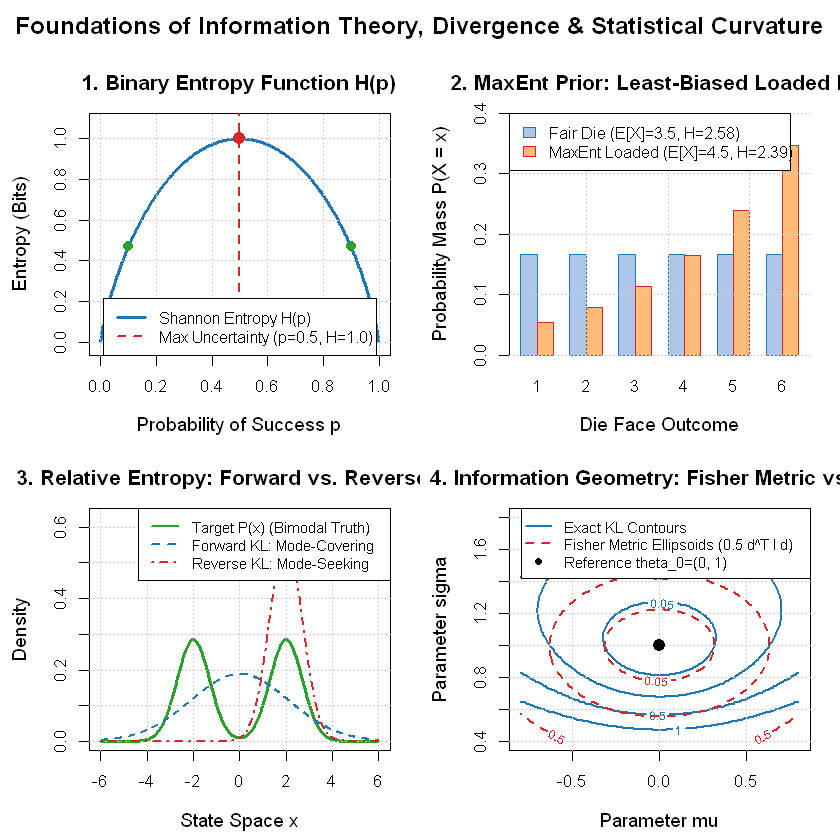

In [6]:
# ==============================================================================
# Master 4-Panel Publication-Grade Visualization in Base R
# ==============================================================================

par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3.2, 1.5), oma = c(0, 0, 2.5, 0), cex.lab = 1.15, cex.main = 1.25)

# ------------------------------------------------------------------------------
# Panel 1: Binary Entropy Function H(p)
# ------------------------------------------------------------------------------
p_grid <- seq(1e-4, 1.0 - 1e-4, length.out = 500)
h_grid <- binary_entropy(p_grid, base = 2)

plot(p_grid, h_grid, type = "l", col = "#1f77b4", lwd = 2.8,
     main = "1. Binary Entropy Function H(p)", xlab = "Probability of Success p", ylab = "Entropy (Bits)",
     ylim = c(-0.02, 1.08))
grid(col = "gray80", lty = "dotted")
abline(v = 0.5, col = "#d62728", lty = 2, lwd = 2.0)
points(0.5, 1.0, col = "#d62728", pch = 19, cex = 1.6)
points(c(0.1, 0.9), c(binary_entropy(0.1), binary_entropy(0.9)), col = "#2ca02c", pch = 19, cex = 1.4)
legend("bottom", legend = c("Shannon Entropy H(p)", "Max Uncertainty (p=0.5, H=1.0)"),
       col = c("#1f77b4", "#d62728"), lty = c(1, 2), lwd = c(2.5, 2), bg = "white", cex = 0.95)

# ------------------------------------------------------------------------------
# Panel 2: MaxEnt Distribution (Loaded Die)
# ------------------------------------------------------------------------------
barplot_data <- rbind(p_fair_die, p_maxent_loaded)
bp <- barplot(barplot_data, beside = TRUE, col = c("#aec7e8", "#ffbb78"),
              border = c("#1f77b4", "#d62728"), names.arg = 1:6,
              main = "2. MaxEnt Prior: Least-Biased Loaded Die",
              xlab = "Die Face Outcome", ylab = "Probability Mass P(X = x)",
              ylim = c(0, 0.40))
grid(col = "gray80", lty = "dotted")
legend("topleft", legend = c("Fair Die (E[X]=3.5, H=2.58)", "MaxEnt Loaded (E[X]=4.5, H=2.39)"),
       fill = c("#aec7e8", "#ffbb78"), border = c("#1f77b4", "#d62728"), bg = "white", cex = 0.95)

# ------------------------------------------------------------------------------
# Panel 3: Forward vs. Reverse KL on Bimodal Target
# ------------------------------------------------------------------------------
x_eval <- seq(-6, 6, length.out = 600)
p_target <- 0.5 * dnorm(x_eval, -2.0, 0.7) + 0.5 * dnorm(x_eval, 2.0, 0.7)
q_forward <- dnorm(x_eval, 0.0, sqrt(0.7^2 + 2.0^2))
q_reverse <- dnorm(x_eval, 2.0, 0.7)

plot(x_eval, p_target, type = "l", col = "#2ca02c", lwd = 2.8,
     main = "3. Relative Entropy: Forward vs. Reverse KL",
     xlab = "State Space x", ylab = "Density", ylim = c(0, max(q_reverse) * 1.1))
grid(col = "gray80", lty = "dotted")
lines(x_eval, q_forward, col = "#1f77b4", lwd = 2.2, lty = 2)
lines(x_eval, q_reverse, col = "#d62728", lwd = 2.2, lty = 4)
legend("topright", legend = c("Target P(x) (Bimodal Truth)", "Forward KL: Mode-Covering", "Reverse KL: Mode-Seeking"),
       col = c("#2ca02c", "#1f77b4", "#d62728"), lty = c(1, 2, 4), lwd = 2.2, bg = "white", cex = 0.90)

# ------------------------------------------------------------------------------
# Panel 4: Statistical Manifold: Fisher Metric vs. Exact KL Contours
# ------------------------------------------------------------------------------
mu_center <- 0.0
sigma_center <- 1.0

mu_vals <- seq(-0.8, 0.8, length.out = 100)
sigma_vals <- seq(0.4, 1.8, length.out = 100)

KL_mat <- matrix(0, nrow = length(mu_vals), ncol = length(sigma_vals))
Fisher_mat <- matrix(0, nrow = length(mu_vals), ncol = length(sigma_vals))

for (i in seq_along(mu_vals)) {
  for (j in seq_along(sigma_vals)) {
    m <- mu_vals[i]
    s <- sigma_vals[j]
    KL_mat[i, j] <- kl_gaussian_continuous_r(mu_center, sigma_center, m, s)
    delta_mu <- m - mu_center
    delta_sigma <- s - sigma_center
    Fisher_mat[i, j] <- 0.5 * ((delta_mu^2)/(sigma_center^2) + 2.0 * (delta_sigma^2)/(sigma_center^2))
  }
}

levels_plot <- c(0.05, 0.2, 0.5, 1.0)
contour(mu_vals, sigma_vals, KL_mat, levels = levels_plot, col = "#1f77b4", lwd = 2.2,
        main = "4. Information Geometry: Fisher Metric vs. KL",
        xlab = "Parameter mu", ylab = "Parameter sigma")
grid(col = "gray80", lty = "dotted")
contour(mu_vals, sigma_vals, Fisher_mat, levels = levels_plot, col = "#d62728", lty = 2, lwd = 1.8, add = TRUE)
points(mu_center, sigma_center, pch = 19, cex = 1.6, col = "black")
legend("topright", legend = c("Exact KL Contours", "Fisher Metric Ellipsoids (0.5 d^T I d)", "Reference theta_0=(0, 1)"),
       col = c("#1f77b4", "#d62728", "black"), lty = c(1, 2, NA), pch = c(NA, NA, 19), lwd = c(2.2, 1.8, NA), bg = "white", cex = 0.88)

title("Foundations of Information Theory, Divergence & Statistical Curvature", outer = TRUE, cex.main = 1.45, font.main = 2)


---

## Summary & Master Conceptual Synthesis

| Quantity | Formula | Invariance | Optimization Role |
| :--- | :--- | :--- | :--- |
| **Shannon Entropy** $H(X)$ | $-\sum p_i \log_2 p_i$ | Discrete: Permutation invariant.<br>Continuous: Scale dependent ($+\log|a|$). | Maximized by MaxEnt priors (Jaynes) under moment constraints. |
| **KL Divergence** $D_{\text{KL}}(P \parallel Q)$ | $\int p(x) \log\frac{p(x)}{q(x)}dx$ | Invariant under smooth coordinate transformations. | Minimized in Variational Inference (Reverse KL) and LOO-CV deviance (Forward KL). |
| **Fisher Information** $\mathcal{I}(\theta)$ | $-\mathbb{E}\left[\nabla_\theta^2 \log p(x \mid \theta)\right]$ | Covariant Riemannian tensor ($J^T \mathcal{I} J$). | Inverted for Laplace MAP covariance ($\Sigma = \mathcal{I}^{-1}$); Cramér-Rao lower bound. |
| **Mutual Information** $I(X; Y)$ | $H(X) - H(X \mid Y)$ | Invariant under individual reparameterizations of $X$ and $Y$. | Maximized in Bayesian active learning & optimal experimental design (EIG). |

---



## ✏️ Check Your Understanding: 3-Tier Scaffolding Exercises

---

### 🟢 Tier 1 (Conceptual Verification): Entropy & Perplexity of Cache Evictions
A database caching layer tracks eviction causes across four categories:
1. `TTL_EXPIRED`: $p_1 = 0.50$
2. `MEMORY_PRESSURE`: $p_2 = 0.25$
3. `EXPLICIT_INVALIDATION`: $p_3 = 0.125$
4. `KEY_OVERWRITE`: $p_4 = 0.125$

**Your Tasks**:
1. Hand-calculate the exact Shannon Entropy $H(X)$ in bits.
2. What is the **Perplexity** of this eviction distribution?
3. If an engineer claims: *"This cache behaves as if it has 5 equally unpredictable eviction modes"*, are they correct? Explain using perplexity.

---



In [7]:
# ============================================================
# 🟢 Tier 1: Your Turn - Attempt the Problem Here in R
# ============================================================

# p_evictions <- c(0.50, 0.25, 0.125, 0.125)
# h_cache <- ...
# perp_cache <- ...
# cat(sprintf("Entropy:    %.2f bits\n", h_cache))
# cat(sprintf("Perplexity: %.3f\n", perp_cache))



<details><summary><b> Click here to view the solution...</b></summary>

#### Step-by-Step Solution:
1. **Shannon Entropy Calculation**:
   $$H(X) = -\left[0.5 \log_2(0.5) + 0.25 \log_2(0.25) + 0.125 \log_2(0.125) + 0.125 \log_2(0.125)\right]$$
   $$H(X) = -\left[0.5(-1) + 0.25(-2) + 0.125(-3) + 0.125(-3)\right]$$
   $$H(X) = -\left[-0.5 - 0.5 - 0.375 - 0.375\right] = 1.75\text{ bits}$$

2. **Perplexity**:
   $$\text{Perplexity} = 2^{H(X)} = 2^{1.75} = 2^{1} \cdot 2^{0.75} \approx 3.364$$

3. **Engineering Verdict**:
   No, the engineer is incorrect. Despite having 4 nominal categories, the concentration of probability on TTL expiration reduces the true effective unpredictability to **$3.36$ equally likely alternatives**, far below 5.

```R
p_evictions = np.array([0.50, 0.25, 0.125, 0.125])
h_cache = shannon_entropy(p_evictions, base=2)
perp_cache = perplexity(p_evictions, base=2)
print(f"Entropy:    {h_cache:.2f} bits")
print(f"Perplexity: {perp_cache:.3f}")
```
</details>



---

### 🟡 Tier 2 (Guided Calculation): Fisher Information as the Curvature of Bernoulli KL
Consider a coin flip model (Bernoulli distribution) with success parameter $\theta$. 
Let the true parameter be $\theta_0$, and consider an alternate model with parameter $\theta = \theta_0 + \delta$.

The exact discrete KL divergence between two Bernoulli distributions is:
$$D_{\text{KL}}(\theta_0 \parallel \theta_0 + \delta) = \theta_0 \log\left(\frac{\theta_0}{\theta_0 + \delta}\right) + (1 - \theta_0) \log\left(\frac{1 - \theta_0}{1 - (\theta_0 + \delta)}\right)$$

**Your Tasks**:
1. Take the second derivative $\frac{d^2}{d\delta^2} D_{\text{KL}}(\theta_0 \parallel \theta_0 + \delta)$ analytically and evaluate it at $\delta = 0$.
2. Verify that this second derivative equals the classical **Bernoulli Fisher Information**:
   $$\mathcal{I}(\theta_0) = \frac{1}{\theta_0(1 - \theta_0)}$$
3. Compute and compare the analytical value vs. numerical central differences for $\theta_0 = 0.20$.

---



In [8]:
# ============================================================
# 🟡 Tier 2: Your Turn - Attempt the Problem Here in R
# ============================================================

# theta_0 <- 0.20
# I_analytical <- 1.0 / (theta_0 * (1.0 - theta_0))
# bernoulli_kl <- function(t0, t) {
#   return(t0 * log(t0 / t) + (1 - t0) * log((1 - t0) / (1 - t)))
# }
# Compute numerical second derivative of bernoulli_kl at delta=0...



<details><summary><b> Click here to view the solution...</b></summary>

#### Step-by-Step Analytical Derivation:
Let $f(\delta) = D_{\text{KL}}(\theta_0 \parallel \theta_0 + \delta) = \theta_0 \log(\theta_0) - \theta_0 \log(\theta_0 + \delta) + (1 - \theta_0)\log(1 - \theta_0) - (1 - \theta_0)\log(1 - \theta_0 - \delta)$.

1. **First Derivative**:
   $$f'(\delta) = -\frac{\theta_0}{\theta_0 + \delta} + \frac{1 - \theta_0}{1 - \theta_0 - \delta}$$
   At $\delta = 0$: $f'(0) = -1 + 1 = 0$.

2. **Second Derivative**:
   $$f''(\delta) = \frac{\theta_0}{(\theta_0 + \delta)^2} + \frac{1 - \theta_0}{(1 - \theta_0 - \delta)^2}$$
   At $\delta = 0$:
   $$f''(0) = \frac{\theta_0}{\theta_0^2} + \frac{1 - \theta_0}{(1 - \theta_0)^2} = \frac{1}{\theta_0} + \frac{1}{1 - \theta_0} = \frac{(1 - \theta_0) + \theta_0}{\theta_0(1 - \theta_0)} = \frac{1}{\theta_0(1 - \theta_0)} = \mathcal{I}(\theta_0)$$

```R
theta_0 = 0.20
I_analytical = 1.0 / (theta_0 * (1.0 - theta_0))

def bernoulli_kl(t0, t):
    t = np.clip(t, 1e-12, 1.0 - 1e-12)
    return t0 * np.log(t0 / t) + (1.0 - t0) * np.log((1.0 - t0) / (1.0 - t))

# Finite difference
h = 1e-5
d2_kl = (bernoulli_kl(theta_0, theta_0 + h) - 2.0 * bernoulli_kl(theta_0, theta_0) + bernoulli_kl(theta_0, theta_0 - h)) / (h**2)

print(f"Analytical Fisher Information: {I_analytical:.6f}")
print(f"Numerical Hessian of KL:       {d2_kl:.6f}")
assert np.isclose(I_analytical, d2_kl, rtol=1e-4)
```
</details>



---

### 🔴 Tier 3 (Production Challenge): Greedy Multi-Stage Optimal Experimentation
You are designing an active telemetry diagnostic system to estimate a hidden server performance parameter $\theta \sim \mathcal{N}(\mu_0 = 0, \sigma_0^2 = 9.0)$ (initial prior standard deviation $\sigma_0 = 3.0$).

You have a total budget of **15.00 USD** and can run sequential probes from three options:
* **Micro-Probe**: Cost = 1.00 USD, Measurement Noise $\sigma_m = 4.0$
* **Standard Diagnostic**: Cost = 3.00 USD, Measurement Noise $\sigma_m = 2.0$
* **Heavy Stress Profiler**: Cost = 7.00 USD, Measurement Noise $\sigma_m = 0.8$

**Your Tasks**:
1. Implement a greedy sequential Bayesian experimental design loop:
   * At each step, evaluate the Expected Information Gain per dollar: $\frac{\text{EIG}(d)}{\text{Cost}(d)}$.
   * Select and execute the highest-efficiency probe.
   * Update the posterior variance $\sigma^2$ analytically via conjugate updating.
   * Deduct probe cost from remaining budget.
   * Stop when budget is exhausted.
2. Compare the final posterior variance $\sigma_{\text{final}}^2$ of this greedy EIG strategy against spending the entire budget exclusively on 15 Micro-Probes or 2 Heavy Stress Profilers.

---



In [9]:
# ============================================================
# 🔴 Tier 3: Your Turn - Attempt the Problem Here in R
# ============================================================

# budget <- 15.0
# sigma_0 <- 3.0
# probes <- list(
#   list(name = "Micro",    sigma_m = 4.0, cost = 1.0),
#   list(name = "Standard", sigma_m = 2.0, cost = 3.0),
#   list(name = "Heavy",    sigma_m = 0.8, cost = 7.0)
# )
# Implement greedy loop in R...



<details><summary><b> Click here to view the solution...</b></summary>

#### Complete Production Solution in Base R:

```R
run_greedy_experiment_designer_r <- function(initial_sigma = 3.0, total_budget = 15.0) {
  probes <- list(
    list(name = "Micro",    sigma_m = 4.0, cost = 1.0),
    list(name = "Standard", sigma_m = 2.0, cost = 3.0),
    list(name = "Heavy",    sigma_m = 0.8, cost = 7.0)
  )
  
  current_sigma <- initial_sigma
  remaining_budget <- total_budget
  history <- list()
  
  repeat {
    # Find affordable probes
    affordable <- list()
    for (p in probes) {
      if (p$cost <= remaining_budget) {
        affordable[[length(affordable) + 1]] <- p
      }
    }
    if (length(affordable) == 0) break
    
    best_probe <- NULL
    best_efficiency <- -1.0
    best_eig <- 0.0
    
    for (p in affordable) {
      eig_bits <- 0.5 * log2(1.0 + (current_sigma^2 / p$sigma_m^2))
      efficiency <- eig_bits / p$cost
      if (efficiency > best_efficiency) {
        best_efficiency <- efficiency
        best_probe <- p
        best_eig <- eig_bits
      }
    }
    
    new_sigma <- sqrt((current_sigma^2 * best_probe$sigma_m^2) / (current_sigma^2 + best_probe$sigma_m^2))
    remaining_budget <- remaining_budget - best_probe$cost
    
    history[[length(history) + 1]] <- list(
      probe = best_probe$name, cost = best_probe$cost, eig_bits = best_eig,
      sigma_before = current_sigma, sigma_after = new_sigma, budget_left = remaining_budget
    )
    current_sigma <- new_sigma
  }
  
  return(list(final_sigma = current_sigma, history = history))
}

res <- run_greedy_experiment_designer_r()
cat(sprintf("Initial Prior StdDev: 3.000\n"))
cat(sprintf("Final Posterior StdDev: %.4f (Variance: %.4f)\n\n", res$final_sigma, res$final_sigma^2))
cat("Execution Sequence in R:\n")
for (h in res$history) {
  cat(sprintf("  Ran %-8s | Cost: $%d | EIG: %.3fb | StdDev: %.3f -> %.3f | Left: $%d\n",
              h$probe, h$cost, h$eig_bits, h$sigma_before, h$sigma_after, h$budget_left))
}

sigma_15_micro <- sqrt(1.0 / (1.0/9.0 + 15.0 * (1.0/16.0)))
sigma_2_heavy  <- sqrt(1.0 / (1.0/9.0 + 2.0 * (1.0/0.64)))
cat(sprintf("\nAlternative: 15 Micro Probes (15 USD) -> Final StdDev: %.4f\n", sigma_15_micro))
cat(sprintf("Alternative: 2 Heavy Probes (14 USD)  -> Final StdDev: %.4f\n", sigma_2_heavy))
cat(sprintf("Greedy EIG Selector (15 USD)          -> Final StdDev: %.4f\n", res$final_sigma))
```
</details>


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 21: Framework Reliability Contracts](21_framework_reliability_and_tolerance_contracts.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* ➡️ **Next**: **[Ch 23: Active Learning & Flake Culprit Search](23_active_learning_and_culprit_search.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 22**: [📖 Conceptual](../conceptual/22_foundations_of_information_theory.ipynb) | [🤖 AI-Native](../ai/22_foundations_of_information_theory.ipynb) | [🐍 Python](../python/22_foundations_of_information_theory.ipynb) | [🔵 R](../r/22_foundations_of_information_theory.ipynb)


